In [2]:
import os, random, time, json, copy
import numpy as np
import pandas as pd

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
import matplotlib.pyplot as plt

In [3]:
# Setup
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
NUM_CLASSES = 10
MAX_EPOCHS = 30
PATIENCE = 5
os.makedirs("results", exist_ok=True)
print("Device:", DEVICE, "| Torch", torch.__version__)

Device: cuda | Torch 2.11.0+cu130


In [4]:
ROOT = "data"
ds_a = datasets.OxfordIIITPet(ROOT, split="trainval", target_types="category", download=True)
ds_b = datasets.OxfordIIITPet(ROOT, split="test", target_types="category", download=True)
all_names = ds_a.classes

# Subset 10 class: 5 Cat & 5 Dog
SELECTED = ["Abyssinian", "Bengal", "Persian", "Siamese", "Sphynx", "Beagle", "Boxer", "Pug", "Samoyed", "Shiba Inu"]
assert all(n in all_names for n in SELECTED), "Class name does not match"
orig2new = {all_names.index(n): i for i, n in enumerate(SELECTED)}

# Combine split (Trainval + Test), 70:15:15
paths = []
labels = []
for ds in (ds_a, ds_b):
    for p, l in zip(ds._images, ds._labels):
        if l in orig2new:
            paths.append(str(p)); labels.append(orig2new[l])
print("Total image:", len(paths))

tr_p, tmp_p, tr_y, tmp_y = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
va_p, te_p, va_y, te_y = train_test_split(tmp_p, tmp_y, test_size=0.50, stratify=tmp_y, random_state=SEED)
print(f"Train: {len(tr_p)} | Val: {len(va_p)} | Test: {len(te_p)}")

# Data Leakage
assert not (set(tr_p) & set(va_p)) and not (set(tr_p) & set(te_p)) and not (set(va_p) & set(te_p)), "Leakage antar split"
print("Class distribution (Train/Val/Test):")
print(pd.DataFrame({"Train": pd.Series(tr_y).value_counts().sort_index(),
                    "Val": pd.Series(va_y).value_counts().sort_index(),
                    "Test": pd.Series(te_y).value_counts().sort_index()}).T)

100%|██████████| 792M/792M [00:29<00:00, 26.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.7MB/s]


Total image: 1996
Train: 1397 | Val: 299 | Test: 300
Class distribution (Train/Val/Test):
         0    1    2    3    4    5    6    7    8    9
Train  139  140  140  139  140  140  139  140  140  140
Val     29   30   30   30   30   30   30   30   30   30
Test    30   30   30   30   30   30   30   30   30   30


In [5]:
# Transformation & DataLoader
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1
eval_tf = WEIGHTS.transforms()   # Resize(256), CenterCrop(224), Normalize, Deterministic
norm_mean = WEIGHTS.transforms().mean
norm_std = WEIGHTS.transforms().std

train_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_mean, std=norm_std),
])
train_noaug = eval_tf

class PetSubset(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.tf(img), self.labels[i]

def make_loader(p, y, tf, shuffle):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(PetSubset(p, y, tf), batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=2, generator=g, pin_memory=True)

val_loader = make_loader(va_p, va_y, eval_tf, False)
test_loader = make_loader(te_p, te_y, eval_tf, False)
train_eval_loader = make_loader(tr_p, tr_y, eval_tf, False)

In [6]:
# Build Model
def build_resnet(mode):
    """Mode: scratch (B1) | extract (B2) | finetune (B3). Return model, param_groups, frozen_modules."""
    if mode == "scratch":
        m = models.resnet18(weights=None)
        m.fc = nn.Linear(512, NUM_CLASSES)
        groups = [{"params": list(m.parameters()), "lr": 1e-3}]
        frozen = []
    else:
        m = models.resnet18(weights=WEIGHTS)
        for p in m.parameters(): p.requires_grad = False
        m.fc = nn.Linear(512, NUM_CLASSES)
        if mode == "extract":
            groups = [{"params": list(m.fc.parameters()), "lr": 1e-3}]
            frozen = [m.conv1, m.bn1, m.layer1, m.layer2, m.layer3, m.layer4]
        else:
            for p in m.layer4.parameters(): p.requires_grad = True
            groups = [{"params": list(m.layer4.parameters()), "lr": 1e-4}, {"params": list(m.fc.parameters()), "lr": 1e-3}]
            frozen = [m.conv1, m.bn1, m.layer1, m.layer2, m.layer3]
    return m, groups, frozen

N_UNFREEZE = 2

def build_effnet():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    for p in m.parameters(): p.requires_grad = False
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
    top = list(m.features[-N_UNFREEZE:])
    for blk in top:
        for p in blk.parameters(): p.requires_grad = True
    groups = [{"params": [p for b in top for p in b.parameters()], "lr": 1e-4}, {"params": list(m.classifier.parameters()), "lr": 1e-3}]
    frozen = list(m.features[:-N_UNFREEZE])
    return m, groups, frozen

In [7]:
# Training loop, early stopping, logging
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None, frozen=()):
    train = optimizer is not None
    model.train(train)
    if train:
        for m in frozen: m.eval()

    tot_loss = 0.0
    preds = []
    ys = []
    probs = []

    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True);
                loss.backward();
                optimizer.step();
            tot_loss += loss.item() * x.size(0)
            probs.append(torch.softmax(out, 1).detach().cpu()); preds.append(out.argmax(1).cpu()); ys.append(y.cpu())
    n = len(loader.dataset)
    preds = torch.cat(preds).numpy()
    ys = torch.cat(ys).numpy()
    probs = torch.cat(probs).numpy()
    return tot_loss / n, accuracy_score(ys, preds), preds, ys, probs

all_results = {}
all_history = {}
all_preds = {}

def run_exp(tag, strategy, build_fn, train_tf):
    set_seed()
    model, groups, frozen = build_fn()
    model.to(DEVICE)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"[{tag}] Trainable: {n_train:,} / {n_total:,}")
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-2)
    train_loader = make_loader(tr_p, tr_y, train_tf, True)

    hist = []
    best_loss = float("inf")
    best_ep = 0
    best_state = None
    bad = 0
    t0 = time.time()

    for ep in range(1, MAX_EPOCHS + 1):
        trl, tra, *_ = run_epoch(model, train_loader, optimizer, frozen)
        vl, va, *_ = run_epoch(model, val_loader)
        hist.append(dict(epoch=ep, train_loss=trl, train_acc=tra, val_loss=vl, val_acc=va))
        print(f"\t => ep{ep:02d} | Train_loss={trl:.4f} | Val_loss={vl:.4f} | Val_acc={va:.4f}")
        if vl < best_loss - 1e-4:
            best_loss, best_ep, bad = vl, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE: print("==Early Stopping=="); break
    train_time = time.time() - t0

    model.load_state_dict(best_state)
    _, val_acc, *_ = run_epoch(model, val_loader)
    _, train_acc_clean, *_ = run_epoch(model, train_eval_loader)
    _, test_acc, pr, ys, pb = run_epoch(model, test_loader)
    res = dict(tag=tag,
               strategy=strategy,
               seed=SEED,
               trainable_params=n_train,
               total_params=n_total,
               lr_groups=[g["lr"] for g in groups],
               epochs_run=len(hist),
               best_epoch=best_ep,
               train_time_s=round(train_time, 1),
               train_acc_clean=train_acc_clean,
               val_acc=val_acc,
               test_acc=test_acc,
               test_macro_f1=f1_score(ys, pr, average="macro"))

    all_results[tag] = res
    all_history[tag] = pd.DataFrame(hist)
    all_preds[tag] = dict(y_true=ys, y_pred=pr, probs=pb)
    json.dump(res, open(f"results/{tag}.json", "w"), indent=2)
    all_history[tag].to_csv(f"results/{tag}_history.csv", index=False)
    print(json.dumps(res, indent=2))

In [8]:
# B1: Baseline from Scratch
run_exp("B1_scratch_aug", "From scratch", lambda: build_resnet("scratch"), train_aug)

[B1_scratch_aug] Trainable: 11,181,642 / 11,181,642
	 => ep01 | Train_loss=2.3782 | Val_loss=2.2027 | Val_acc=0.2040
	 => ep02 | Train_loss=2.0877 | Val_loss=2.0677 | Val_acc=0.2776
	 => ep03 | Train_loss=1.9851 | Val_loss=2.1103 | Val_acc=0.2375
	 => ep04 | Train_loss=1.9143 | Val_loss=1.9161 | Val_acc=0.3344
	 => ep05 | Train_loss=1.7758 | Val_loss=1.9509 | Val_acc=0.3311
	 => ep06 | Train_loss=1.7207 | Val_loss=1.7649 | Val_acc=0.3880
	 => ep07 | Train_loss=1.7321 | Val_loss=1.9265 | Val_acc=0.3244
	 => ep08 | Train_loss=1.5953 | Val_loss=2.3008 | Val_acc=0.3478
	 => ep09 | Train_loss=1.5730 | Val_loss=1.6003 | Val_acc=0.4783
	 => ep10 | Train_loss=1.4620 | Val_loss=1.8072 | Val_acc=0.4013
	 => ep11 | Train_loss=1.4197 | Val_loss=2.2843 | Val_acc=0.3378
	 => ep12 | Train_loss=1.3223 | Val_loss=1.5495 | Val_acc=0.5117
	 => ep13 | Train_loss=1.2721 | Val_loss=2.1926 | Val_acc=0.4147
	 => ep14 | Train_loss=1.1926 | Val_loss=1.6621 | Val_acc=0.4749
	 => ep15 | Train_loss=1.1264 | Val_lo

In [9]:
# B2: Feature Extraction
run_exp("B2_extract_aug", "Feature extraction", lambda: build_resnet("extract"), train_aug)
assert all_results["B2_extract_aug"]["trainable_params"] == 5130

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 164MB/s]


[B2_extract_aug] Trainable: 5,130 / 11,181,642
	 => ep01 | Train_loss=1.1414 | Val_loss=0.4575 | Val_acc=0.9298
	 => ep02 | Train_loss=0.3649 | Val_loss=0.2481 | Val_acc=0.9632
	 => ep03 | Train_loss=0.2498 | Val_loss=0.2022 | Val_acc=0.9599
	 => ep04 | Train_loss=0.1956 | Val_loss=0.1534 | Val_acc=0.9766
	 => ep05 | Train_loss=0.1597 | Val_loss=0.1433 | Val_acc=0.9766
	 => ep06 | Train_loss=0.1525 | Val_loss=0.1255 | Val_acc=0.9799
	 => ep07 | Train_loss=0.1307 | Val_loss=0.1165 | Val_acc=0.9833
	 => ep08 | Train_loss=0.1204 | Val_loss=0.1068 | Val_acc=0.9866
	 => ep09 | Train_loss=0.1046 | Val_loss=0.1116 | Val_acc=0.9833
	 => ep10 | Train_loss=0.0941 | Val_loss=0.1027 | Val_acc=0.9799
	 => ep11 | Train_loss=0.0949 | Val_loss=0.0981 | Val_acc=0.9833
	 => ep12 | Train_loss=0.0915 | Val_loss=0.1095 | Val_acc=0.9766
	 => ep13 | Train_loss=0.0881 | Val_loss=0.0969 | Val_acc=0.9799
	 => ep14 | Train_loss=0.0754 | Val_loss=0.0912 | Val_acc=0.9799
	 => ep15 | Train_loss=0.0770 | Val_loss=0.

In [10]:
# B3: Progressive Fine-Tuning
run_exp("B3_finetune_aug", "Fine-tuning layer4+fc", lambda: build_resnet("finetune"), train_aug)

[B3_finetune_aug] Trainable: 8,398,858 / 11,181,642
	 => ep01 | Train_loss=0.6076 | Val_loss=0.1348 | Val_acc=0.9599
	 => ep02 | Train_loss=0.1225 | Val_loss=0.0930 | Val_acc=0.9732
	 => ep03 | Train_loss=0.0692 | Val_loss=0.1038 | Val_acc=0.9732
	 => ep04 | Train_loss=0.0363 | Val_loss=0.0765 | Val_acc=0.9766
	 => ep05 | Train_loss=0.0242 | Val_loss=0.0776 | Val_acc=0.9799
	 => ep06 | Train_loss=0.0197 | Val_loss=0.0759 | Val_acc=0.9732
	 => ep07 | Train_loss=0.0191 | Val_loss=0.0814 | Val_acc=0.9766
	 => ep08 | Train_loss=0.0158 | Val_loss=0.0765 | Val_acc=0.9833
	 => ep09 | Train_loss=0.0108 | Val_loss=0.0868 | Val_acc=0.9732
	 => ep10 | Train_loss=0.0143 | Val_loss=0.0892 | Val_acc=0.9732
	 => ep11 | Train_loss=0.0090 | Val_loss=0.0953 | Val_acc=0.9732
==Early Stopping==
{
  "tag": "B3_finetune_aug",
  "strategy": "Fine-tuning layer4+fc",
  "seed": 42,
  "trainable_params": 8398858,
  "total_params": 11181642,
  "lr_groups": [
    0.0001,
    0.001
  ],
  "epochs_run": 11,
  "best_

In [11]:
# B4: Uji Kontrol Data Augmentation
run_exp("B4_finetune_noaug", "Fine-tuning layer4+fc (tanpa aug)", lambda: build_resnet("finetune"), train_noaug)

[B4_finetune_noaug] Trainable: 8,398,858 / 11,181,642
	 => ep01 | Train_loss=0.5283 | Val_loss=0.1164 | Val_acc=0.9599
	 => ep02 | Train_loss=0.0524 | Val_loss=0.0920 | Val_acc=0.9699
	 => ep03 | Train_loss=0.0155 | Val_loss=0.0880 | Val_acc=0.9766
	 => ep04 | Train_loss=0.0092 | Val_loss=0.0824 | Val_acc=0.9732
	 => ep05 | Train_loss=0.0049 | Val_loss=0.0826 | Val_acc=0.9732
	 => ep06 | Train_loss=0.0050 | Val_loss=0.0892 | Val_acc=0.9732
	 => ep07 | Train_loss=0.0035 | Val_loss=0.0879 | Val_acc=0.9766
	 => ep08 | Train_loss=0.0027 | Val_loss=0.0885 | Val_acc=0.9699
	 => ep09 | Train_loss=0.0021 | Val_loss=0.0881 | Val_acc=0.9732
==Early Stopping==
{
  "tag": "B4_finetune_noaug",
  "strategy": "Fine-tuning layer4+fc (tanpa aug)",
  "seed": 42,
  "trainable_params": 8398858,
  "total_params": 11181642,
  "lr_groups": [
    0.0001,
    0.001
  ],
  "epochs_run": 9,
  "best_epoch": 4,
  "train_time_s": 86.4,
  "train_acc_clean": 1.0,
  "val_acc": 0.9732441471571907,
  "test_acc": 0.97666

In [12]:
# B5: Bonus EfficientNet-B0
run_exp("B5_effnet_b0_aug", "EfficientNet-B0 fine-tune", build_effnet, train_aug)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 139MB/s]


[B5_effnet_b0_aug] Trainable: 1,142,202 / 4,020,358
	 => ep01 | Train_loss=0.9017 | Val_loss=0.1399 | Val_acc=0.9866
	 => ep02 | Train_loss=0.1491 | Val_loss=0.0736 | Val_acc=0.9866
	 => ep03 | Train_loss=0.0920 | Val_loss=0.0615 | Val_acc=0.9833
	 => ep04 | Train_loss=0.0676 | Val_loss=0.0517 | Val_acc=0.9866
	 => ep05 | Train_loss=0.0448 | Val_loss=0.0497 | Val_acc=0.9833
	 => ep06 | Train_loss=0.0394 | Val_loss=0.0493 | Val_acc=0.9833
	 => ep07 | Train_loss=0.0360 | Val_loss=0.0439 | Val_acc=0.9900
	 => ep08 | Train_loss=0.0249 | Val_loss=0.0397 | Val_acc=0.9866
	 => ep09 | Train_loss=0.0216 | Val_loss=0.0380 | Val_acc=0.9900
	 => ep10 | Train_loss=0.0150 | Val_loss=0.0405 | Val_acc=0.9866
	 => ep11 | Train_loss=0.0160 | Val_loss=0.0455 | Val_acc=0.9900
	 => ep12 | Train_loss=0.0124 | Val_loss=0.0401 | Val_acc=0.9866
	 => ep13 | Train_loss=0.0110 | Val_loss=0.0413 | Val_acc=0.9833
	 => ep14 | Train_loss=0.0093 | Val_loss=0.0469 | Val_acc=0.9866
==Early Stopping==
{
  "tag": "B5_effn

In [13]:
# Consolidation Table & Raw logs
df = pd.DataFrame(all_results.values())
df["gap_train_val"] = df["train_acc_clean"] - df["val_acc"]
df.to_csv("results/summary.csv", index=False)
df[["tag", "strategy", "trainable_params", "lr_groups", "best_epoch", "epochs_run", "train_time_s", "train_acc_clean", "val_acc", "gap_train_val", "test_macro_f1"]]

,tag,strategy,trainable_params,lr_groups,best_epoch,epochs_run,train_time_s,train_acc_clean,val_acc,gap_train_val,test_macro_f1
0,B1_scratch_aug,From scratch,11181642,[0.001],12,17,243.6,0.542591,0.511706,0.030886,0.448381
1,B2_extract_aug,Feature extraction,5130,[0.001],27,30,395.7,0.994989,0.986622,0.008367,0.966777
2,B3_finetune_aug,Fine-tuning layer4+fc,8398858,"[0.0001, 0.001]",6,11,145.1,0.994989,0.973244,0.021745,0.973327
3,B4_finetune_noaug,Fine-tuning layer4+fc (tanpa aug),8398858,"[0.0001, 0.001]",4,9,86.4,1.000000,0.973244,0.026756,0.976518
4,B5_effnet_b0_aug,EfficientNet-B0 fine-tune,1142202,"[0.0001, 0.001]",9,14,186.9,0.998568,0.989967,0.008602,0.980107


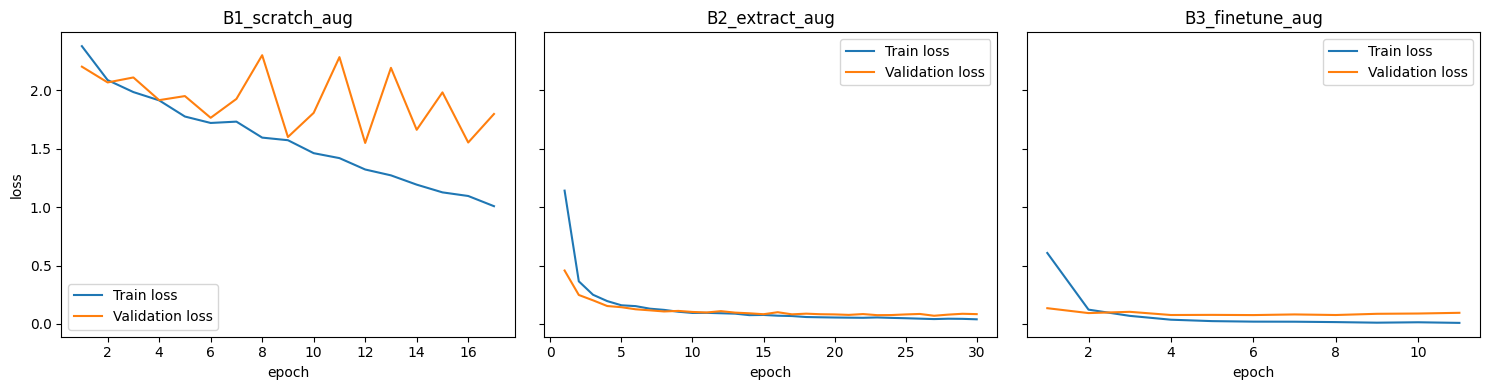

In [14]:
# Training vs Validation loss
tags = ["B1_scratch_aug", "B2_extract_aug", "B3_finetune_aug"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, t in zip(axes, tags):
    h = all_history[t]
    ax.plot(h.epoch, h.train_loss, label="Train loss");
    ax.plot(h.epoch, h.val_loss, label="Validation loss");
    ax.set_title(t); ax.set_xlabel("epoch");
    ax.legend();
axes[0].set_ylabel("loss");
plt.tight_layout(); plt.savefig("results/loss_curves.png", dpi=150);
plt.show()

Best Model: B5_effnet_b0_aug | Wrong Total: 6


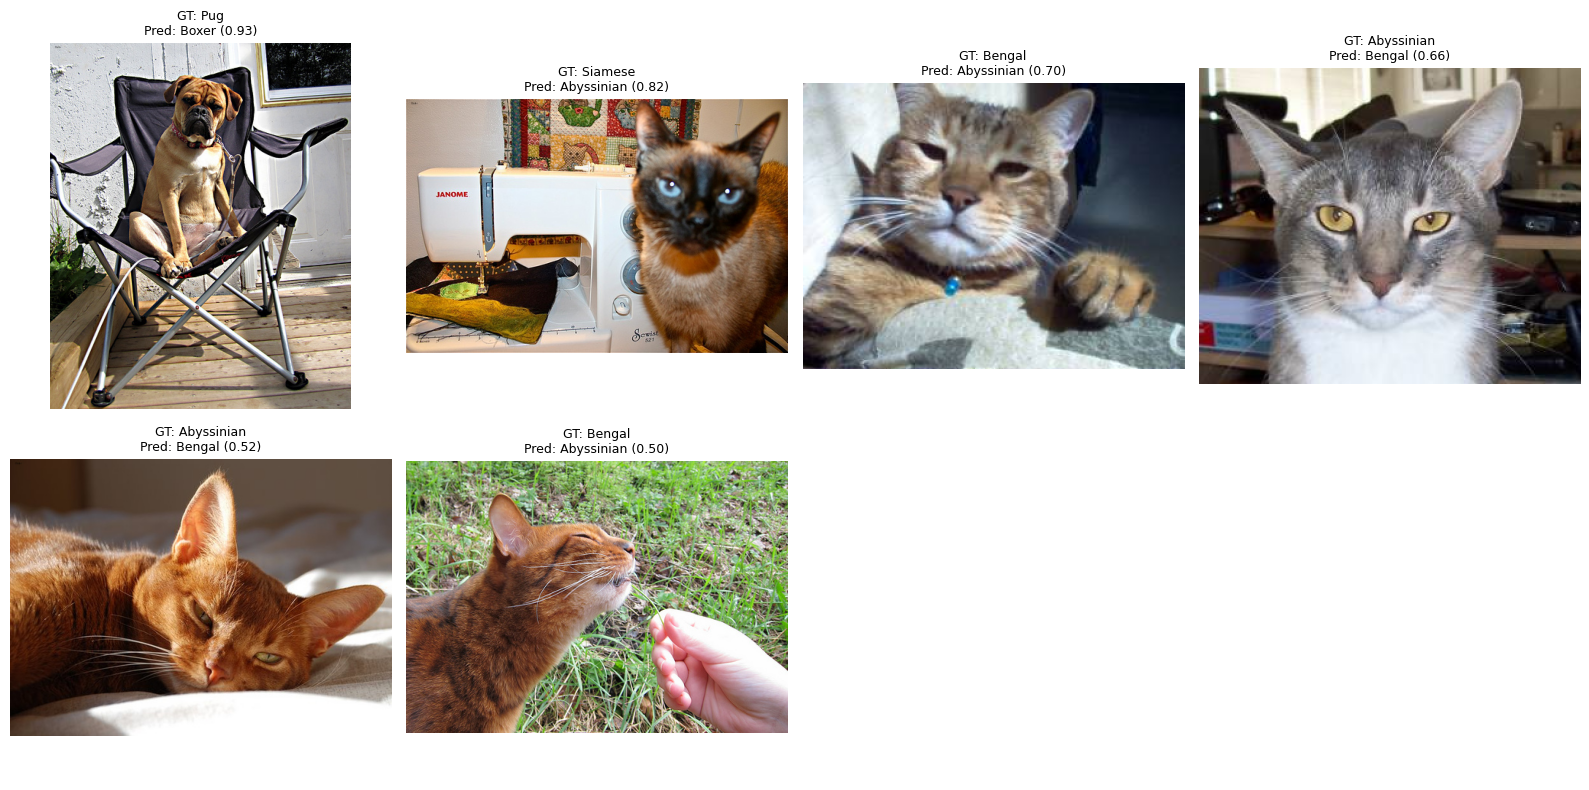

In [15]:
# Failure Analysis
best_tag = df.sort_values("test_macro_f1", ascending=False).iloc[0]["tag"]
P = all_preds[best_tag]
wrong = np.where(P["y_true"] != P["y_pred"])[0]
conf = P["probs"][wrong, P["y_pred"][wrong]]
show = wrong[np.argsort(-conf)][:8] # Max 8 sample, from highest confidence
print("Best Model:", best_tag, "| Wrong Total:", len(wrong))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(Image.open(te_p[i]).convert("RGB"));
    ax.axis("off");
    ax.set_title(f"GT: {SELECTED[P['y_true'][i]]}\nPred: {SELECTED[P['y_pred'][i]]} ({P['probs'][i].max():.2f})", fontsize=9)
for ax in axes.ravel()[len(show):]: ax.axis("off")
plt.tight_layout();
plt.savefig("results/failure_analysis.png", dpi=150);
plt.show()

In [16]:
import PIL, sklearn, torchvision, matplotlib

config = dict(seed=SEED,
              batch_size=BATCH_SIZE,
              max_epochs=MAX_EPOCHS,
              patience=PATIENCE,
              optimizer="AdamW",
              weight_decay=1e-2,
              selected_classes=SELECTED,
              split="70/15/15 stratified",
              n_train=len(tr_p),
              n_val=len(va_p),
              n_test=len(te_p),
              torch=torch.__version__,
              torchvision=torchvision.__version__,
              device=str(DEVICE),
              gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
json.dump(config, open("results/config.json", "w"), indent=2)

# requirements.txt
for name, mod in {"torch": torch, "torchvision": torchvision, "scikit-learn": sklearn, "pandas": pd, "numpy": np, "matplotlib": matplotlib, "pillow": PIL}.items():
    print(f"{name}=={mod.__version__.split('+')[0]}")

torch==2.11.0
torchvision==0.26.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
pillow==11.3.0
